# <div align="center"><span style="color:red">Final project</span></div>

# Subject : Detection and Segmentation of Brain Tumors from MRI Images Using a 3D U-Net

### Name : Alireza Kalbassi
### Student Number : 9938193

----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### importing the necessary libararies : 

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import nibabel as nib
import os
import random
import torchio as tio
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.networks.utils import one_hot

### checking if there is a GPU available : 

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


# Loading the dataset :

In [8]:
path_dataset = "./Brats2021"

we need to define a dataset class to load the dataset.     
dataset class needs to have some necessary methods :
1. first of all, we need to create the __init__ method. this is the place we define all of the objects. all the other methods use this to access the objects they need.

2. __len__ : this is the method that returns the number of samples in the dataset. 

3. **retrieve_image :** there are 4 3D images per sample. this method loads each image separately and stacks them all together at the end to form a sample with 4 channels. the shape of each sample will be like (4, H, W, D).

4. **retrieve mask :** this is the method that returns the specified masks by their given index. 

5. **index_list :** we use this method to identify the existing folders. we loop through the main folder. for each folder we check if the files in it are damaged or can't be loaded for any reason. after making sure that all the files are intact, we add the folders name to the "total_index" list. we use this list for accessing the samples. 
loading all the files in this part takes a lot more time than simply checking the syntax of each file. However, I worked on BraTS 2020 dataset before this project and that version of dataset had 2 damaged files which I detected using the same technique. Therefore, I decided to accept this inefficiency to prevent any issue in the future.

6. __getitem__ : this is the method we use to return the images and masks one by one. this method gets the specified image and its mask and converts their structure to the acceptable structure of pytorch. it then checks if there is a transform specified in the class input and executes it on the image. at last, it returns the image and its mask at the output. in the beginning of this method we translate the given index into its index_name because retrieve_image and retrieve_mask methods need the exact name of the folder. 

In [9]:
class BraTSDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.total_index = self.index_list()
    
    def __len__(self):
        return len(self.total_index)
    
    def __getitem__(self, idx):
        index_name = self.total_index[idx]
        image = self.retrieve_image(index_name)
        mask = self.retrieve_mask(index_name)
        image = torch.from_numpy(image).float() # pytorch expects tensors but get_fdata function returns np.arrays
        mask = torch.tensor(mask).long() # crossentropyloss expects tensors with long dtype 

        return image, mask

    def retrieve_image(self, index_name):
        image_name = index_name
        image_layer1_path = os.path.join(self.root_dir, image_name , f"{image_name}_flair.nii.gz")
        image_layer2_path = os.path.join(self.root_dir, image_name , f"{image_name}_t1.nii.gz")
        image_layer3_path = os.path.join(self.root_dir, image_name , f"{image_name}_t1ce.nii.gz")
        image_layer4_path = os.path.join(self.root_dir, image_name , f"{image_name}_t2.nii.gz")

        image_layer1 = nib.load(image_layer1_path)
        image_layer2 = nib.load(image_layer2_path)
        image_layer3 = nib.load(image_layer3_path)
        image_layer4 = nib.load(image_layer4_path)

        image_layer1 = image_layer1.get_fdata(dtype=np.float32)
        image_layer2 = image_layer2.get_fdata(dtype=np.float32)
        image_layer3 = image_layer3.get_fdata(dtype=np.float32)
        image_layer4 = image_layer4.get_fdata(dtype=np.float32)

        image = np.stack([image_layer1, image_layer2, image_layer3, image_layer4])
        
        return image
    
    def retrieve_mask(self, index_name):
        mask_name = index_name
        mask_path = os.path.join(self.root_dir, mask_name, f"{mask_name}_seg.nii.gz")
        mask = nib.load(mask_path)
        mask = mask.get_fdata(dtype=np.float32)
        return mask
        
    def index_list(self):
        total_index = []
        for case in sorted(os.listdir(self.root_dir)):
            if os.path.isdir(os.path.join(self.root_dir, case)):
                try:
                    _ = self.retrieve_image(case)
                    _ = self.retrieve_mask(case)
                    total_index.append(os.path.basename(case))

                except Exception as e:
                    print(f"an error occurred during image {case}'s loading :\n{e}")
        return total_index

In [10]:
dataset = BraTSDataset(path_dataset)

In [11]:
print(f"number of samples in the dataset : {len(dataset)}")

image, mask = dataset[1000]
print(f"\nshape of the image : {image.shape} \nshape of the mask : {mask.shape}")

number of samples in the dataset : 1251

shape of the image : torch.Size([4, 240, 240, 155]) 
shape of the mask : torch.Size([240, 240, 155])


### defining a class for Normalizing by sample : 
    there are two problems with normalizing MRI images. 
    
    1. first, there is a lot of black space around the brain's image. these black space voxels have a value of zero, which skews the mean and standard deviation toward zero. to solve this problem we applied a not_zero mask on each image and only kept the voxels whose values are not zero.

    2. the second problem is, each channel has very different structure and therefore different mean and standard deviation. so first, we split the input into its four modality images. then we calculate the mean and standard deviation of each image independently and we stack the images together once again.

In [12]:
class Normalizer():
    def __call__(self, x):
        flair = x[0, :, :, :]
        t1 = x[1, :, :, :]
        t1_ce = x[2, :, :, :]
        t2 = x[3, :, :, :]
        
        flair_mean = flair[flair != 0].mean()
        t1_mean = t1[t1 != 0].mean()
        t1ce_mean = t1_ce[t1_ce != 0].mean()
        t2_mean = t2[t2 != 0].mean()

        flair_std = flair[flair != 0].std()
        t1_std = t1[t1 != 0].std()
        t1ce_std = t1_ce[t1_ce != 0].std()
        t2_std = t2[t2 != 0].std()

        normalized_flair = (flair - flair_mean) / (flair_std + 1e-6)
        normalized_t1 = (t1 - t1_mean) / (t1_std + 1e-6)
        normalized_t1ce = (t1_ce - t1ce_mean) / (t1ce_std + 1e-6)
        normalized_t2 = (t2 - t2_mean) / (t2_std + 1e-6)

        normalized_sample = torch.stack([normalized_flair, normalized_t1, normalized_t1ce, normalized_t2])
        
        return normalized_sample

unfortunately pytorch's transform module doesn't support 3D augmentation therefore we need to use an extra library named torchIO. torchIO is a library built for working specifically with medical images. 

in the class below, we have defined two steps of augmentation. the first one is RandomGamma which changes the brightness of image and the second one is RandomElasticDeformation which changes the shape of the object in the image. 

ScalarImage/LabelMap functions expects 4D inputs so we have unsqueezed the mask to reshape it into a 4D tensor. it also expects a subject containing both image and the mask because some transforms should be applied on only images but others should be applied on both image and its mask. so we need to know which one is image and which one is the mask so torchIO can tell them apart and apply the correct transform behavior to each. we also need to extract the underlying tensor using .data at the end. finally we squeeze the mask again reshape it into its original form.

the selection of these two specific augmentations was based on a paper that has compared the different augmentation methods for 3D-Unets. the link of the paper would be available in the project's documentation.

In [13]:
class Augmentation():
    def __init__(self):
        self.transform = tio.Compose([
                    tio.RandomGamma(),
                    tio.RandomElasticDeformation()
                ])

    def __call__(self, subject):
        transformed_subject = self.transform(subject)
        return transformed_subject

In [14]:
normalizer = Normalizer()
augmentation = Augmentation()
image, mask = dataset[1000]
print(f"\nshape of the image : {image.shape} \nshape of the mask : {mask.shape}")
print(image.mean())
print(torch.isnan(image).any())
print(torch.isinf(image).any())
print(torch.unique(mask))
print()

image = normalizer(image)
print(f"\nshape of the image : {image.shape} \nshape of the mask : {mask.shape}")
print(image.mean())
print(torch.isnan(image).any())
print(torch.isinf(image).any())
print(torch.unique(mask))
print()


shape of the image : torch.Size([4, 240, 240, 155]) 
shape of the mask : torch.Size([240, 240, 155])
tensor(55.9725)
tensor(False)
tensor(False)
tensor([0, 1, 2, 4])


shape of the image : torch.Size([4, 240, 240, 155]) 
shape of the mask : torch.Size([240, 240, 155])
tensor(-2.7300)
tensor(False)
tensor(False)
tensor([0, 1, 2, 4])



In [15]:
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(dataset, [0.7, 0.15, 0.15], generator=generator)

the full volume of these images is too large for GPU's memory. also most of the image's voxels are background or no tumor. therefore we only use small patches of each sample for training. in order to do this, we use torchIO's LabelSampler. the LabelSampler class gets a torchIO subject in the input and creates a patch from that sample. we need to specify a patch_size for this class. after searching the web i found out patch_size of 128 is usual for this dataset. 

there is another important thing that needs to be decided. we can either take out a random patch from each sample or we can take patches around some specific mask numbers. i decided to give each types of tumor areas a chance of 30% (giving a total chance of 90% to the tumor voxels overall) and give the background a chance of 10% to be the center of the patch. the reason i did this is, in medical images like this dataset, it is far more important to detect every single tumor voxel than detecting a background voxel as tumor. 

In [16]:
class Patch_extractor():
    def __init__(self, patch_size = 128):
        self.sampler = tio.LabelSampler(
                    patch_size= patch_size,
                    label_name= "mask",
                    label_probabilities={0:1, 1:3, 2:3, 3:3}
                )
    def __call__(self, subject):
        patched_subject = next(self.sampler(subject))
        return patched_subject


considering the fact that we have three seperate datasets, we need to define a new class just for transformation. we apply the normalization on all three of them but the train_dataset, needs augmentation in addition to normalization.

there is a consideration when we are defining the transformation class, RandomGamma function we defined earlier, expects positive numbers. therefore normalization should be after the augmentation.

In [17]:
class Subset_with_transform():
    def __init__(self, subset, patch_extractor, augmentation = None, normalizer = None):
        self.augmentation = augmentation
        self.normalizer = normalizer
        self.subset = subset
        self.patch_extractor = patch_extractor

    def __getitem__(self, idx):
        image, mask = self.subset[idx]

        mask[mask == 4] = 3

        mask = mask.unsqueeze(0)
        
        subject = tio.Subject(
                image = tio.ScalarImage(tensor= image),
                mask = tio.LabelMap(tensor= mask)
            )

        subject = self.patch_extractor(subject)
        
        if self.augmentation is not None : 
            subject = self.augmentation(subject)

        
        image = subject['image'].data
        mask = subject['mask'].data

        if self.normalizer is not None:
            image = self.normalizer(image)

        return image, mask

    def __len__(self):
        return len(self.subset)

In [18]:
patch_extractor = Patch_extractor()
transformed_train_dataset = Subset_with_transform(train_dataset, patch_extractor=patch_extractor, augmentation=augmentation, normalizer=normalizer)
transformed_val_dataset = Subset_with_transform(val_dataset, patch_extractor=patch_extractor, normalizer=normalizer)

In [19]:
print(f"Length of total dataset :     {len(dataset)}")
print(f"Length of training dataset:   {len(train_dataset)}")
print(f"Length of validation dataset: {len(val_dataset)}")
print(f"Length of test dataset:       {len(test_dataset)}")

Length of total dataset :     1251
Length of training dataset:   876
Length of validation dataset: 188
Length of test dataset:       187


In [20]:
image, mask = transformed_train_dataset[0]
print(f"\nshape of the image : {image.shape} \nshape of the mask : {mask.shape}")
print(image.mean())
print(torch.isnan(image).any())
print(torch.isinf(image).any())
print(torch.unique(mask))
print()

image, mask = transformed_val_dataset[0]
print(f"\nshape of the image : {image.shape} \nshape of the mask : {mask.shape}")
print(image.mean())
print(torch.isnan(image).any())
print(torch.isinf(image).any())
print(torch.unique(mask))
print()


shape of the image : torch.Size([4, 128, 128, 128]) 
shape of the mask : torch.Size([1, 128, 128, 128])
tensor(-1.3513)
tensor(False)
tensor(False)
tensor([0., 1., 2., 3.])


shape of the image : torch.Size([4, 128, 128, 128]) 
shape of the mask : torch.Size([1, 128, 128, 128])
tensor(-1.8931)
tensor(False)
tensor(False)
tensor([0, 1, 2, 3])



we define a dataloader for each of the datasets. validation and test datasets don't need shuffling. 

In [21]:
batch_size = 4
train_loader = DataLoader(transformed_train_dataset, batch_size=batch_size, shuffle=True, num_workers=12, pin_memory=True)
val_loader = DataLoader(transformed_val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

In [22]:
image, mask = next(iter(train_loader))
print(image.shape)
print(mask.shape)

torch.Size([4, 4, 128, 128, 128])
torch.Size([4, 1, 128, 128, 128])


## defining the CNN : 
first we define some conv block classes to avoid writing the same layers several times and keep the code cleaner and easier to debug.

usually two classes (a downlayer and an uplayer)  would be enough but in this case it is easier to use four classes because of the firt and last layer's diffrences from other layers. this approach also keeps the main U-net class cleaner and easier to read and edit. 

In [23]:
class First_DownLayer(nn.Module):
    def __init__(self):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv3d(in_channels=4, out_channels=32, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),

            nn.Conv3d(in_channels=32, out_channels=64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(64),
            nn.ReLU()    
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [24]:
class DownLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool3d(kernel_size=2, stride=2),

            nn.Conv3d(in_channels=in_channels, out_channels=in_channels, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(in_channels),
            nn.ReLU(),

            nn.Conv3d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [25]:
class UpLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv3d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(),

            nn.Conv3d(in_channels=out_channels, out_channels=out_channels, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(),

            nn.ConvTranspose3d(in_channels=out_channels, out_channels=out_channels, kernel_size=2, stride=2)
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [26]:
class Last_UpLayer(nn.Module):
    def __init__(self):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv3d(in_channels=192, out_channels=64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),

            nn.Conv3d(in_channels=64, out_channels=64, kernel_size=3, padding=1, stride=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),

            nn.Conv3d(in_channels=64, out_channels=4, kernel_size=3, padding=1, stride=1)
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [27]:
class U_net(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.level1 = First_DownLayer()
        self.level2 = DownLayer(64, 128)
        self.level3 = DownLayer(128, 256)
        self.level4 = DownLayer(256, 512)

        self.transpose = nn.ConvTranspose3d(in_channels=512, out_channels=512, kernel_size=2, stride=2)

        self.level5 = UpLayer(768, 256)
        self.level6 = UpLayer(384, 128)
        self.level7 = Last_UpLayer()

    def forward(self, x):
        x1 = self.level1(x)
        x2 = self.level2(x1)
        x3 = self.level3(x2)
        x4 = self.level4(x3)

        x4 = self.transpose(x4)

        x4 = torch.concat([x3, x4], dim=1)
        x5 = self.level5(x4)

        x5 = torch.concat([x2, x5], dim=1)
        x6 = self.level6(x5)

        x6 = torch.concat([x1, x6], dim=1)
        output = self.level7(x6)
        
        return output

there is a problem with the usual crossentropyloss. we are working with medical images. these kind of images have a lot of background space but just a very tiny tumoric space. the problem this kind of structure creates is that the model can get a very low loss by predicting every voxel as background. this is an enormous problem because it is very dangerous to predict tumor voxels as background. to solve this problem we use dice loss. dice loss calculates the loss for each class individually and then returns the average. but there is a problem with dice loss too. dice loss can be hard to converge at the beginning, so we use the sum of crossentropyloss and dice loss to address this problem.

we use Monai library for implementing this loss function. Monai library has a class that does the exact same thing called DiceCELoss. the to_onehot_y parameter converts the mask into 4 individual mask. each mask holds the values for its mask number. for example, if voxel no.1 has value of 2, channels zero, one and three would have a value of 0 for that voxel and channel 2 would have a value of 1. 

for the same reasons as above we use Dice metric for monitoring the model's performance. dice metric returns a list of four numbers. each number represents the score of a mask number. 
**reduction="none"** tells the function to return four numbers instead of averaging them and returning a single number.

In [28]:
loss_function = DiceCELoss(
    to_onehot_y=True,
    softmax=True,
    lambda_dice=1,
    lambda_ce=1
)

dice_metric = DiceMetric(include_background=True, reduction="mean_batch")

in order to use the dice metric, first we need to give each voxel a label. we use **"argmax"** to see which label has the highest value. after getting the labels, we need to onehot encode both the prediction mask and the real mask because dice metric expects onehot encoded inputs. we use the **"onehot"** function to do this. at last we call the dice metric function to store that step's scores internally. we do these steps for each batch of samples. after finishing all the samples, we call **"dice_metric.aggregate()"**. this function uses all the gathered information and returns four scores, one for each label. we use **"tolist"** to turn these values into a python list. 
as mentioned before, "dice metric" stores each step's scores. therefore we need to reset these values before going to the next step. we use **".reset()"** for that.

In [29]:
def training_loop(model, train_loader, val_loader, loss_function, optimizer, num_epochs, device):
    model.to(device)
    train_loss = []
    val_loss = []
    val_dice = []
    best_dice = 0

    scaler = torch.amp.GradScaler('cuda')


    print("--- Training Started ---")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        total = len(train_loader.dataset)
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = loss_function(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item() * labels.size(0)

        train_loss.append(running_loss / total)

        model.eval()
        running_loss = 0.0
        total = len(val_loader.dataset)

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = loss_function(outputs, labels)

                running_loss += loss.item() * labels.size(0)

                predicted = outputs.argmax(dim=1, keepdim=True)
                predicted_onehot = one_hot(predicted, num_classes=4)
                labels_onehot = one_hot(labels, num_classes=4)

                dice_metric(y_pred=predicted_onehot, y=labels_onehot)

            val_loss.append(running_loss / total)
            epoch_dice = dice_metric.aggregate().tolist()
            dice_metric.reset()
            val_dice.append(epoch_dice)

            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss[epoch]:.4f}, Val Loss: {val_loss[epoch]:.4f}, Val Dice: {val_dice[epoch]}")

            torch.save(model.state_dict(), 'latest_model.pth')

            mean_tumor_dice = sum(epoch_dice[1:]) / len(epoch_dice[1:])
            if mean_tumor_dice > best_dice:
                best_dice = mean_tumor_dice
                torch.save(model.state_dict(), 'best_model.pth')
                print(f"New best model saved (mean tumor Dice: {best_dice:.4f})")

    print("--- Finished Training ---")

    metrics = [train_loss, val_loss, val_dice]

    return model, metrics

we need full volume prediction for the test. we also need full volume prediction for any given image in the future. therefore we need to design a test loop that works on full size volumes.

next problem is the lack of accuracy at the edges of samples. the reason behind this is that voxels around the edges have fewer surrounding neighbors therefore filters can't work properly on them. to solve this problem we compute the output for patches of samples that have overlap with each other and take an average for the common voxels. 

as we already know from earlier blocks, torchIO functions work with torchIO subject, therefore we need to first create a subject for each sample. 

after defining the subject, we use **"tio.inference.GridSampler()"**. this class gives our specified patch size and patch overlap in the input and gives us patches of our sample. the returned patches will cover the entire image and have a specified overlap with each other.

the next step is creating a dataloader that gets a sample in the input and gives us the calculated patches from the previous step, batch by batch. we use **"tio.SubjectsLoader()"** for this step. this function gets the result of GridSampler in the input and gives us a dataloader. 

the last class we need is the **"tio.inference.GridAggregator"**. we use this one to stick together the predicted values of individual patches. 

in the dataloader's loop, first we get the image and location of the patch dataloader gives us. we use **"tio.DATA"** and **"tio.LOCATION"** for this part. then we normalize the values of the given image because the model is used to see normalized values. finally we use **"aggregator.add_batch()"** to stick the calculated values to the main image. 

after finishing the loop, first we use **"aggregator.get_output_tensor()"** to get the full size prediction of the given sample.

loss function expects a 5D input, therefore we "unsqueeze" the predicted output and the main mask before giving them to the loss function. predicted output is a 4D tensor itself because it lacks the batch dimension. also main mask is a 4D tensor too because it lacks the channel dimension. when both of these problems are fixed the dimension structure of both of them will be (batch, channel, height, width, depth)

In [59]:
def test(model, test_loader, loss_function, device):
    model.to(device)

    patch_size = 128, 128, 128
    patch_overlap = 16, 16, 16
    running_loss = 0.0

    model.eval()
    with torch.no_grad():
        for image, mask in test_loader:
            image, mask = image.to(device), mask.to(device)
            mask[mask == 4] = 3

            subject = tio.Subject(
                image = tio.ScalarImage(tensor=image.squeeze(0)),
                mask = tio.LabelMap(tensor=mask)
            )

            grid_sampler = tio.inference.GridSampler(
                subject,
                patch_size, 
                patch_overlap
            )

            patch_loader = tio.SubjectsLoader(grid_sampler, batch_size=batch_size)
            aggregator = tio.inference.GridAggregator(grid_sampler)

            for patches in patch_loader:
                image = patches['image'][tio.DATA]
                locations = patches[tio.LOCATION]
                image = torch.stack([normalizer(img) for img in image])
                image = image.to(device)

                outputs = model(image)
                aggregator.add_batch(outputs, locations)

            outputs = aggregator.get_output_tensor()  
            outputs = outputs.unsqueeze(0).to(device)
            mask = mask.unsqueeze(1).to(device)
            loss = loss_function(outputs, mask)
            running_loss += loss.item() * mask.size(0)

            predicted = outputs.argmax(dim=1, keepdim=True)
            predicted_onehot = one_hot(predicted, num_classes=4)
            mask_onehot = one_hot(mask, num_classes=4)
            dice_metric(y_pred=predicted_onehot, y=mask_onehot)

        total = len(test_loader.dataset)
        loss = (running_loss / total)
        dice_score = dice_metric.aggregate().tolist()
        dice_metric.reset()

        return loss, dice_score

In [28]:
for _ in range(20):
    model = U_net()
    lr = 10 ** random.uniform(-2, -4)
    weight_decay = 10 ** random.uniform(-3, -5)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    trained_model, training_metrics = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=5,
    device=device)

    print(f"learning rate : {lr}        weight_decay : {weight_decay}       metrics : {training_metrics}")

    del model, optimizer, trained_model
    torch.cuda.empty_cache()

--- Training Started ---
Epoch [1/5], Train Loss: 0.4843, Val Loss: 0.6959, Val Dice: [0.4845515191555023]
Epoch [2/5], Train Loss: 0.3685, Val Loss: 0.4129, Val Dice: [0.7050089836120605]
Epoch [3/5], Train Loss: 0.3302, Val Loss: 0.4210, Val Dice: [0.6881581544876099]
Epoch [4/5], Train Loss: 0.3123, Val Loss: 0.3171, Val Dice: [0.7679194808006287]
Epoch [5/5], Train Loss: 0.2913, Val Loss: 0.2949, Val Dice: [0.7890827059745789]
--- Finished Training ---
learning rate : 0.0002186399825178458        weight_decay : 4.83510184509715e-05       metrics : [[0.4843028074802329, 0.3684841787025809, 0.33022986434093893, 0.31228348565156056, 0.2912675496105734], [0.6958818828805964, 0.4128965484969159, 0.42103079373532154, 0.3170519420441161, 0.29491664817992674], [[0.4845515191555023], [0.7050089836120605], [0.6881581544876099], [0.7679194808006287], [0.7890827059745789]]]
--- Training Started ---
Epoch [1/5], Train Loss: 0.5245, Val Loss: 0.5040, Val Dice: [0.6164941191673279]
Epoch [2/5], T

KeyboardInterrupt: 

In [34]:
for _ in range(14):
    model = U_net()
    lr = 10 ** random.uniform(-2, -4)
    weight_decay = 10 ** random.uniform(-3, -5)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    trained_model, training_metrics = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=5,
    device=device)

    print(f"learning rate : {lr}        weight_decay : {weight_decay}       metrics : {training_metrics}")

    del model, optimizer, trained_model
    torch.cuda.empty_cache()

--- Training Started ---
Epoch [1/5], Train Loss: 0.6449, Val Loss: 0.6512, Val Dice: [0.5959196090698242]
Epoch [2/5], Train Loss: 0.4746, Val Loss: 0.4522, Val Dice: [0.6641725897789001]
Epoch [3/5], Train Loss: 0.4562, Val Loss: 0.5129, Val Dice: [0.5925997495651245]
Epoch [4/5], Train Loss: 0.4437, Val Loss: 0.5564, Val Dice: [0.585387110710144]
Epoch [5/5], Train Loss: 0.4344, Val Loss: 0.4557, Val Dice: [0.6613488793373108]
--- Finished Training ---
learning rate : 0.0068457496358000315        weight_decay : 0.00018284354261205376       metrics : [[0.6448557246221255, 0.47460119147278945, 0.45619900368120025, 0.44374466160116677, 0.43442851345833033], [0.6511707318590042, 0.45216661945302433, 0.5128836815661573, 0.5563710211439336, 0.4556682420537827], [[0.5959196090698242], [0.6641725897789001], [0.5925997495651245], [0.585387110710144], [0.6613488793373108]]]
--- Training Started ---
Epoch [1/5], Train Loss: 0.5227, Val Loss: 0.3957, Val Dice: [0.7069322466850281]
Epoch [2/5], 

In [46]:
model = U_net()
optimizer = optim.Adam(model.parameters(), lr=0.0002, weight_decay=0.000023)

print(model)

U_net(
  (level1): First_DownLayer(
    (block): Sequential(
      (0): Conv3d(4, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
    )
  )
  (level2): DownLayer(
    (block): Sequential(
      (0): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (2): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (3): ReLU()
      (4): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (5): BatchNorm3d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU()
    )
  )
  (l

In [52]:
total_training_metrics = []
total_num_epochs = 0

In [58]:
num_epochs = 50

trained_model, training_metrics = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=num_epochs,
    device=device
)

--- Training Started ---


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d92b7156480>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/opt/conda/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d92b7156480>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", l

Epoch [1/50], Train Loss: 0.1857, Val Loss: 0.2033, Val Dice: [0.9963182210922241, 0.7783528566360474, 0.8015081286430359, 0.8594100475311279]
New best model saved (mean tumor Dice: 0.8131)


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d92b7156480>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/opt/conda/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d92b7156480>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.12/site-packages/torch/utils/data/dataloader.py", l

Epoch [2/50], Train Loss: 0.1824, Val Loss: 0.1881, Val Dice: [0.9973590970039368, 0.7772465348243713, 0.8411617875099182, 0.8685332536697388]
New best model saved (mean tumor Dice: 0.8290)
Epoch [3/50], Train Loss: 0.1783, Val Loss: 0.1928, Val Dice: [0.9973878860473633, 0.7793979048728943, 0.8278849124908447, 0.8622511625289917]
Epoch [4/50], Train Loss: 0.1792, Val Loss: 0.1868, Val Dice: [0.9973568320274353, 0.7842912077903748, 0.8393994569778442, 0.8626582026481628]
Epoch [5/50], Train Loss: 0.1830, Val Loss: 0.1989, Val Dice: [0.9970139861106873, 0.778208315372467, 0.8193954825401306, 0.8522782921791077]
Epoch [6/50], Train Loss: 0.1770, Val Loss: 0.1942, Val Dice: [0.9974820017814636, 0.7887076735496521, 0.8358367085456848, 0.8700088262557983]
New best model saved (mean tumor Dice: 0.8315)
Epoch [7/50], Train Loss: 0.1795, Val Loss: 0.1852, Val Dice: [0.9974359273910522, 0.7846388816833496, 0.8451614379882812, 0.8515211939811707]
Epoch [8/50], Train Loss: 0.1830, Val Loss: 0.187

In [61]:
if not total_training_metrics:
    total_training_metrics = [list(m) for m in training_metrics]
else:
    for i in range(3):
        total_training_metrics[i] += training_metrics[i]
        
total_num_epochs += num_epochs

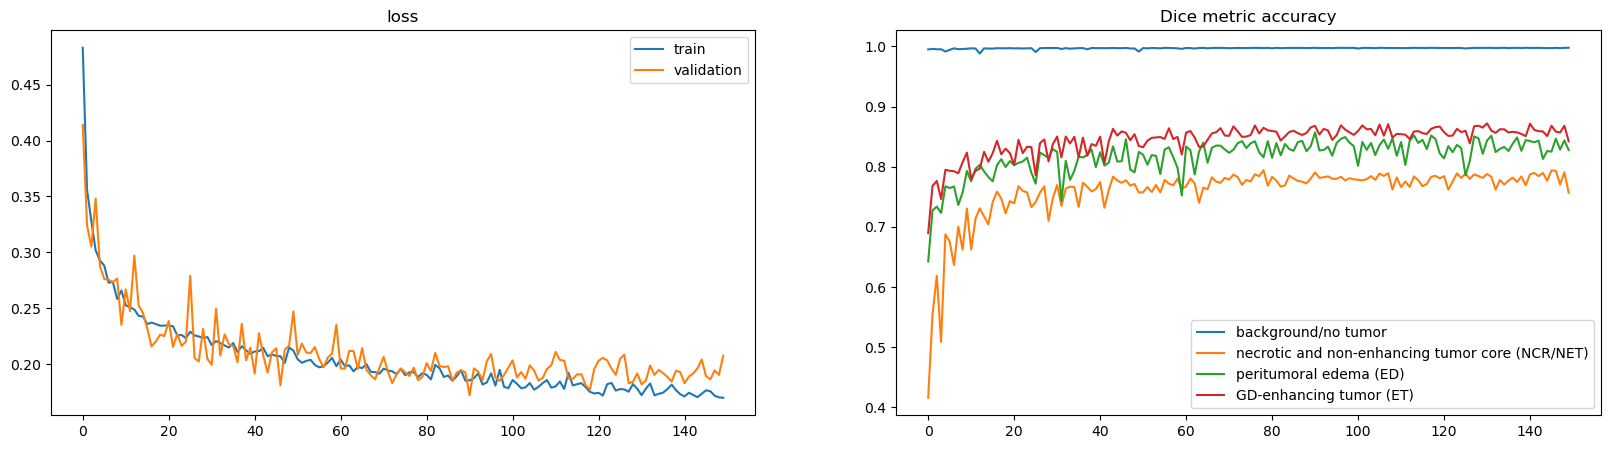

In [62]:
val_dice_score = np.array(total_training_metrics[2])

plt.figure(figsize=(20,5))

plt.subplot(1, 2, 1)
plt.plot(range(total_num_epochs), total_training_metrics[0], label="train")
plt.plot(range(total_num_epochs), total_training_metrics[1], label="validation")
plt.title("loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(total_num_epochs), val_dice_score[:, 0], label="background/no tumor")
plt.plot(range(total_num_epochs), val_dice_score[:, 1], label="necrotic and non-enhancing tumor core (NCR/NET)")
plt.plot(range(total_num_epochs), val_dice_score[:, 2], label="peritumoral edema (ED)")
plt.plot(range(total_num_epochs), val_dice_score[:, 3], label="GD-enhancing tumor (ET)")
plt.title("Dice metric accuracy")
plt.legend()

plt.show()

In [63]:
model.load_state_dict(torch.load('best_model.pth'))

<All keys matched successfully>

Test results : 

loss: 0.1641526769268959
background/no tumor dice score: 99.92051720619202%
necrotic and non-enhancing tumor core (NCR/NET) dice score: 75.17487406730652%
peritumoral edema (ED) dice score: 82.7350378036499%
GD-enhancing tumor (ET) dice score: 87.00693249702454%


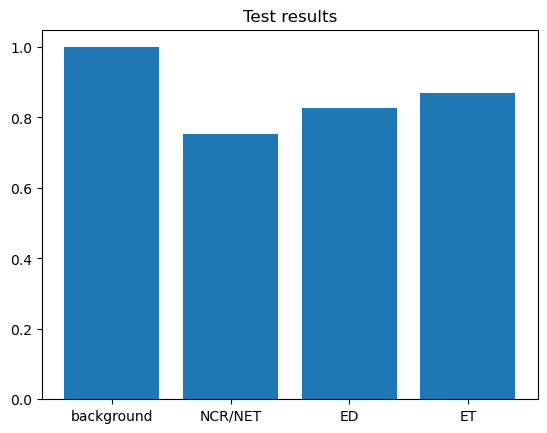

In [64]:
loss, dice_score = test(model=model, test_loader=test_loader, loss_function=loss_function, device=device)

print(f"Test results : \n")
print(f"loss: {loss}")
print(f"background/no tumor dice score: {dice_score[0] * 100}%")
print(f"necrotic and non-enhancing tumor core (NCR/NET) dice score: {dice_score[1] * 100}%")
print(f"peritumoral edema (ED) dice score: {dice_score[2] * 100}%")
print(f"GD-enhancing tumor (ET) dice score: {dice_score[3] * 100}%")

x = ['background', 'NCR/NET', 'ED', 'ET']
y = [dice_score[0], dice_score[1], dice_score[2], dice_score[3]]
plt.bar(x, y)
plt.title("Test results")
plt.show()